# Which habitat associations survive stronger controls? — REAL DATA

This exploratory extension corrects an important limitation of notebook 05 and
adds direct habitat pairs, quality restriction, presence and influence checks.
The original supplement has **20 genomes with only `s__` as species**, across six
genera. That unresolved rank cannot establish conspecificity. Notebook 05 pooled
it as a species; those historical fits remain visible but are superseded here.
We exclude unresolved assignments from species-based inference and preserve them
in the 1,964-genome descriptive registry. We do not guess ANI clusters by genus.

The protocol and correction were committed before their respective fits. This
is a secondary exploratory analysis of Macrel small-ORF candidates, a distinct
endpoint from archaeome encrypted APEX windows. Species membership and genomic
GC are incomplete ancestry/composition controls; screened-ORF denominators,
strain phylogeny and source-study controls are still missing. Ecological lineage
sorting can itself be real biology; within-species comparisons answer a narrower
question than total habitat differences.

In [1]:
from pathlib import Path
import json,sys,tempfile,subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/genomespot_lens').exists())
DATA=ROOT/'examples/ecology-robustness'
BASE=ROOT/'examples/lactobacillaceae-ecology'
provenance=json.loads((DATA/'provenance.json').read_text());assert provenance['data_kind']=='real'
registry=pd.read_csv(DATA/'registry-with-taxonomy-status.csv')
excluded=pd.read_csv(DATA/'unresolved-species-exclusions.csv')
assert len(excluded)==20 and excluded.genus.nunique()==6
assert not excluded.resolved_joint_model_eligible.any()
display(excluded.groupby(['genus','habitat']).size().rename('unresolved genomes'))
print('Descriptive registry:',len(registry),'genomes; resolved labels:',registry[registry.species_resolved].species.nunique())

genus                 habitat       
Companilactobacillus  animal            1
Lacticaseibacillus    fermented food    1
Lactobacillus         animal            2
                      fermented food    1
Ligilactobacillus     animal            3
                      human             3
Limosilactobacillus   animal            7
Pediococcus           animal            2
Name: unresolved genomes, dtype: int64

Descriptive registry: 1964 genomes; resolved labels: 136


## Refit the corrected models and all influence checks

The following cell reruns the real analysis from the frozen registry, including
all 12 direct specifications, four corrected joint models, 35 joint species
omissions and every direct-count species omission. Compare numerical results
with the exported artifacts using floating-point tolerances. No simulated
fallback or remote model service is used.

In [2]:
with tempfile.TemporaryDirectory() as folder:
    temp=Path(folder)
    for script,out in [('analyze_ecology_robustness.py',temp/'main'),
                       ('audit_ecology_pair_influence.py',temp/'pairs')]:
        completed=subprocess.run([sys.executable,str(ROOT/'scripts'/script),'--data',str(BASE),'--out',str(out)],
            capture_output=True,text=True,check=True)
    effects=pd.read_csv(temp/'main/direct-effects.csv')
    corrected=pd.read_csv(temp/'main/corrected-joint-effects.csv')
    influence=pd.read_csv(temp/'pairs/direct-pair-influence.csv')
    for actual,saved,keys in [
        (effects,DATA/'direct-effects.csv',['effect','ci_low','ci_high','p_value']),
        (corrected,DATA/'corrected-joint-effects.csv',['rate_ratio','ci_low','ci_high']),
        (influence,DATA/'pair-influence/direct-pair-influence.csv',['effect','ci_low','ci_high'])]:
        stored=pd.read_csv(saved)
        assert len(actual)==len(stored)
        for name in keys:assert np.allclose(actual[name],stored[name],rtol=1e-6,atol=1e-9,equal_nan=True)
print('All recomputed estimates agree with frozen real-data artifacts.')
display(corrected[corrected.contrast.eq('fermented food / human')][
    ['model','genomes','species_clusters','rate_ratio','ci_low','ci_high']])

All recomputed estimates agree with frozen real-data artifacts.


,model,genomes,species_clusters,rate_ratio,ci_low,ci_high
2,crude_resolved_registry,1944,136,1.887006,1.193353,2.983852
5,crude_resolved_common,1292,35,1.537425,0.893333,2.645908
8,species_resolved_common,1292,35,1.100698,0.807815,1.499769
11,species_quality_resolved_common,1292,35,1.017071,0.746532,1.385651


## Direct pair support and distinct endpoints

For every pair, retain only species represented in both habitats, recalculating
support after completeness >=90% and contamination <5% filtering. Require at least
ten informative species clusters and a full-rank model. Count models retain
individual zeros but exclude all-zero species. Binomial presence models require
within-species variation in presence; their odds ratios use different cohorts
and must not be called count rate ratios. Nonconverged/extreme fits are withheld.

All models include species effects, log genome size, completeness, contamination
and GC. Species-cluster sandwich t intervals use clusters-1 df. Holm correction
covers three contrasts within each endpoint/quality family, conservatively
including unestimable contrasts as p=1. These are exploratory tests.

,endpoint,quality,contrast,genomes,species_clusters,status,effect,ci_low,ci_high,p_value,p_holm_three_contrasts
0,count,published,human / animal,1092,18,fit_pass,0.724370,0.530243,0.989568,0.043542,0.130625
1,count,published,fermented food / animal,209,14,fit_pass,1.077872,0.542238,2.142614,0.817263,1.000000
2,count,published,fermented food / human,234,17,fit_pass,0.920244,0.623978,1.357179,0.656273,1.000000
3,presence,published,human / animal,1085,17,fit_pass,0.659104,0.292517,1.485103,0.292773,0.878318
4,presence,published,fermented food / animal,204,12,fit_pass,0.974831,0.256573,3.703801,0.967227,1.000000
5,presence,published,fermented food / human,234,17,fit_pass,0.950446,0.293462,3.078248,0.928090,1.000000
6,count,high,human / animal,379,16,fit_pass,0.555085,0.398248,0.773686,0.001821,0.005464
7,count,high,fermented food / animal,35,9,insufficient_support,NaN,NaN,NaN,NaN,NaN
8,count,high,fermented food / human,108,13,fit_pass,0.789506,0.465556,1.338872,0.348818,0.697637
9,presence,high,human / animal,365,13,fit_pass,0.444289,0.154426,1.278235,0.120238,0.360713


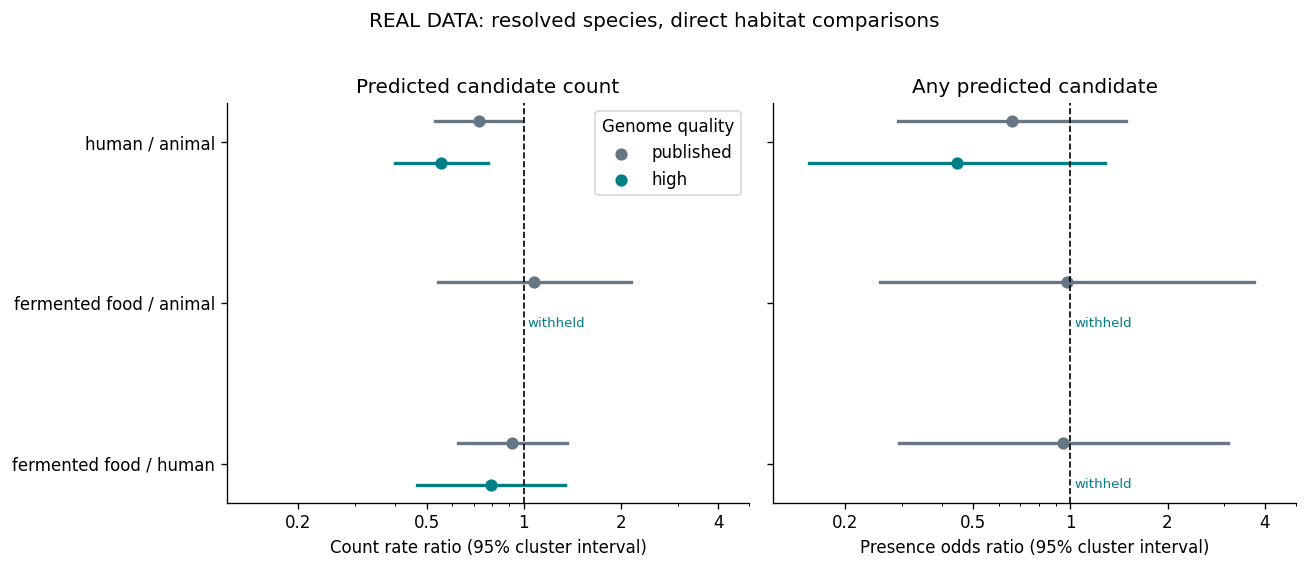

In [3]:
display(effects[['endpoint','quality','contrast','genomes','species_clusters','status',
                 'effect','ci_low','ci_high','p_value','p_holm_three_contrasts']])
FIG=ROOT/'study/ecology-comparison/figures';FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
fig,axes=plt.subplots(1,2,figsize=(11,4.6),sharey=True)
contrasts=['human / animal','fermented food / animal','fermented food / human']
for ax,endpoint in zip(axes,['count','presence']):
    for j,contrast in enumerate(contrasts):
        for quality,shift,color in [('published',-.13,'#667684'),('high',.13,'#007f86')]:
            r=effects[(effects.contrast==contrast)&(effects.endpoint==endpoint)&(effects.quality==quality)].iloc[0]
            if r.status=='fit_pass':
                ax.plot([r.ci_low,r.ci_high],[j+shift]*2,color=color,lw=2)
                ax.scatter(r.effect,j+shift,color=color,s=40,label=quality if j==0 else None)
            else:ax.text(1.03,j+shift,'withheld',color=color,va='center',fontsize=8)
    ax.axvline(1,color='black',ls='--',lw=1);ax.set_xscale('log')
    ax.set_xticks([.2,.5,1,2,4],['0.2','0.5','1','2','4']);ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set(xlim=(.12,5),xlabel=('Count rate ratio' if endpoint=='count' else 'Presence odds ratio')+' (95% cluster interval)',
           title='Predicted candidate count' if endpoint=='count' else 'Any predicted candidate')
axes[0].set_yticks(range(3),contrasts);axes[0].invert_yaxis();axes[0].legend(title='Genome quality')
fig.suptitle('REAL DATA: resolved species, direct habitat comparisons',y=1.02)
fig.tight_layout()
for fmt in ['png','svg']:fig.savefig(FIG/f'direct_habitat_robustness.{fmt}',dpi=180,bbox_inches='tight')
plt.show()

## Influence and the surviving exploratory lead

The high-quality human/animal count contrast is **0.56** (95% cluster interval
0.40–0.77; Holm p≈0.0055 within its three-contrast family), from **379 genomes /
16 resolved species**. Omitting each species produces point estimates 0.53–0.63;
15 of 16 unadjusted omission intervals remain below 1. One crosses 1, so interval
exclusion is not invariant. No omitted species is selected as a new discovery.

Presence is less precise: OR 0.44 (0.15–1.28), with 365 genomes / 13 species.
This does not prove a count-specific biological mechanism; the endpoints have
different cohorts, uncertainty and estimands. The stricter food/animal count
comparison has only nine species, and its presence comparison six, so both are
withheld. The high-quality food/human presence fit is also withheld for extreme
coefficients/nonconvergence. Do not silently report these as null results.

In [4]:
summary=pd.read_csv(DATA/'pair-influence/pair-influence-summary.csv')
display(summary)
lead=influence[(influence.quality=='high')&(influence.contrast=='human / animal')]
assert len(lead)==16 and lead.status.eq('fit_pass').all()
display(lead[['excluded_species','genomes','effect','ci_low','ci_high']])
print('An omission whose interval reaches 1:')
display(lead[lead.ci_high.ge(1)][['excluded_species','effect','ci_low','ci_high']])

,quality,contrast,omissions,estimable_omissions,insufficient_support,minimum_effect,maximum_effect,intervals_below_one,intervals_above_one
0,high,fermented food / animal,9,0,9,NaN,NaN,0,0
1,high,fermented food / human,13,13,0,0.692887,0.972788,0,0
2,high,human / animal,16,16,0,0.528261,0.631874,15,0
3,published,fermented food / animal,14,14,0,0.882934,1.249718,0,0
4,published,fermented food / human,17,17,0,0.856356,1.074930,0,0
5,published,human / animal,18,18,0,0.666495,0.824833,9,0


,excluded_species,genomes,effect,ci_low,ci_high
49,s__Lacticaseibacillus paracasei,358,0.545689,0.392209,0.759229
50,s__Lactiplantibacillus plantarum,372,0.528861,0.382068,0.732054
51,s__Lactobacillus acidophilus,375,0.540045,0.389412,0.748945
52,s__Lactobacillus amylovorus,372,0.551226,0.387861,0.783398
53,s__Lactobacillus crispatus,355,0.528261,0.371247,0.751683
54,s__Lactobacillus sp027681045,374,0.547542,0.391494,0.765791
55,s__Lactobacillus sp945980025,349,0.562218,0.395223,0.799775
56,s__Ligilactobacillus ruminis,336,0.569335,0.403333,0.803659
57,s__Ligilactobacillus sp945923665,309,0.631874,0.392797,1.016466
58,s__Limosilactobacillus intestinavium,375,0.559915,0.398600,0.786515


An omission whose interval reaches 1:


,excluded_species,effect,ci_low,ci_high
57,s__Ligilactobacillus sp945923665,0.631874,0.392797,1.016466


## Research decision

The corrected joint food/human count estimate is **1.02 (0.75–1.39)**, and the
direct pair estimate **0.92 (0.62–1.36)**. The earlier crude food advantage still
fails these within-species checks. The animal/human count difference is a useful
lead for independent verification, not evidence that a niche increases measured
antimicrobial activity. Full strain phylogeny, proteome composition, exact ORF
screening opportunities and source-study independence remain necessary before
claiming survival of *all* ancestry/composition/coverage controls.

For AllTheBacteria, the deeper public search has not located the original score /
parent / genome export. A released Bakta proteome independently contains 33.3
million distinct 8–50-aa windows, versus 3.9 million reported for the screen.
Its original screen membership is unknown; this is a conditional scope audit,
not proof the paper's total is wrong or a recovered screen. The exact cohort,
fragment-generation procedure and conflicting MIC selection rules require
clarification. See `study/atb-export-search-2026-10-21.md` and the prepared data
request. We do not invent screened zeros or rerun a substitute screen as if it
were the original one.